In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv('/content/used_car_dataset.csv')
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (9582, 11)


,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001,23,"98,000 km",Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,Innova,2009,15,190000.0 km,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,VentoTest,2010,14,"77,246 km",Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017,7,"83,500 km",Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,2019,5,"45,000 km",Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"


In [2]:
print("Data Types:")
print(df.dtypes)

Data Types:
Brand           object
model           object
Year             int64
Age              int64
kmDriven        object
Transmission    object
Owner           object
FuelType        object
PostedDate      object
AdditionInfo    object
AskPrice        object
dtype: object


In [3]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Brand            0
model            0
Year             0
Age              0
kmDriven        47
Transmission     0
Owner            0
FuelType         0
PostedDate       0
AdditionInfo     0
AskPrice         0
dtype: int64


In [4]:
print("\nDuplicated Rows:")
print(df.duplicated().sum())


Duplicated Rows:
724


In [5]:
print("\nDataset Statistics:")
display(df.describe(include="all").T)


Dataset Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Brand,9582,39,Maruti Suzuki,2720,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,9582,400,City,330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,9582.0,NaN,NaN,NaN,2016.361094,4.087226,1986.0,2014.0,2017.0,2019.0,2024.0
Age,9582.0,NaN,NaN,NaN,7.638906,4.087226,0.0,5.0,7.0,10.0,38.0
kmDriven,9535,1910,"65,000 km",198,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,9582,2,Manual,4800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,9582,2,first,4800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FuelType,9582,3,Diesel,3840,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PostedDate,9582,12,Nov-24,8693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AdditionInfo,9582,7307,"BMW 5 Series 3.0 530D M Sport, 2016, Diesel",26,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df = df.drop_duplicates()
df['kmDriven'] = (
    df['kmDriven'].astype(str)
    .str.replace(',', '', regex=False)
    .str.replace(' km', '', regex=False)
)

df['kmDriven'] = pd.to_numeric(df['kmDriven'], errors='coerce')
df['AskPrice'] = (
    df['AskPrice'].astype(str)
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)

df['AskPrice'] = pd.to_numeric(df['AskPrice'], errors='coerce')
df = df.dropna(subset=['kmDriven', 'AskPrice'])

print("Dataset shape after cleaning:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)


Dataset shape after cleaning: (8812, 11)

Missing Values:
Brand           0
model           0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
PostedDate      0
AdditionInfo    0
AskPrice        0
dtype: int64

Data Types:
Brand            object
model            object
Year              int64
Age               int64
kmDriven        float64
Transmission     object
Owner            object
FuelType         object
PostedDate       object
AdditionInfo     object
AskPrice          int64
dtype: object


In [7]:
print("Car Price Statistics:")
print(
    df['AskPrice'].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)
print("\n10 Most Expensive Cars:")
display(
    df.nlargest(10, 'AskPrice')[
        ['Brand', 'model', 'Year', 'Age', 'kmDriven', 'AskPrice']
    ]
)

Car Price Statistics:
count    8.812000e+03
mean     1.042024e+06
std      1.653017e+06
min      1.500000e+04
50%      5.900000e+05
75%      1.075000e+06
90%      2.100000e+06
95%      3.400000e+06
99%      7.655750e+06
max      4.250000e+07
Name: AskPrice, dtype: float64

10 Most Expensive Cars:


,Brand,model,Year,Age,kmDriven,AskPrice
3331,Rolls-Royce,Phantom Series II,2015,9,11500.0,42500000
962,Lexus,LX,2024,0,24000.0,27750000
331,Aston Martin,Vanquish,2016,8,25700.0,26400000
811,Mercedes-Benz,G Class,2019,5,59000.0,26000000
5767,Mercedes-Benz,G Class,2019,5,59000.0,24900000
1187,Toyota,Land Cruiser,2023,1,15000.0,24700000
7435,Mercedes-Benz,SL-Class,2024,0,1400.0,24500000
9241,Mercedes-Benz,AMG,2024,0,16000.0,21500000
5621,BMW,7 Series,2023,1,7000.0,18500000
7615,Bentley,Flying Spur,2017,7,22000.0,18500000


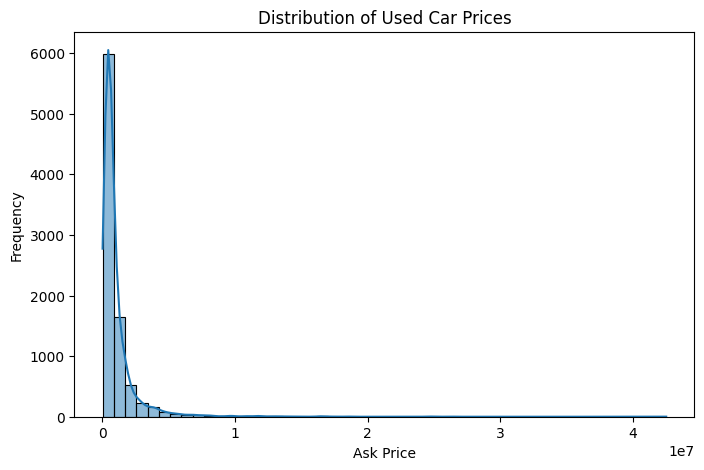

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(df['AskPrice'], bins=50, kde=True)
plt.title('Distribution of Used Car Prices')
plt.xlabel('Ask Price')
plt.ylabel('Frequency')
plt.show()

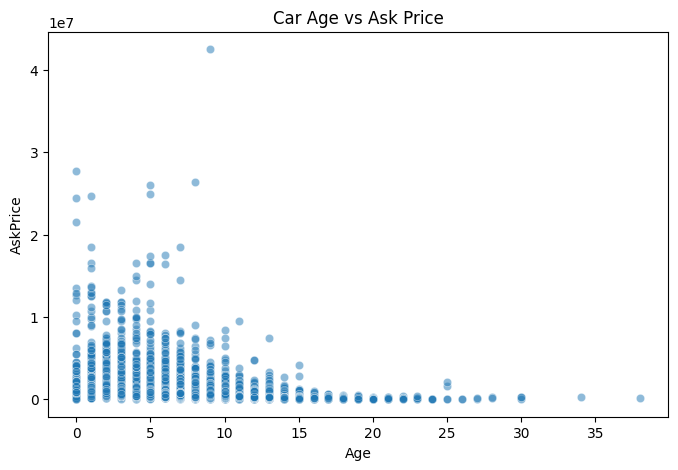

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Age', y='AskPrice', alpha=0.5)
plt.title('Car Age vs Ask Price')
plt.show()


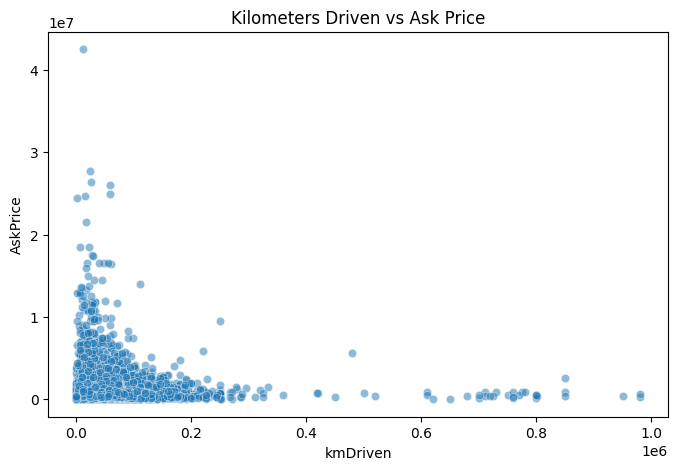

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='kmDriven', y='AskPrice', alpha=0.5)
plt.title('Kilometers Driven vs Ask Price')
plt.show()

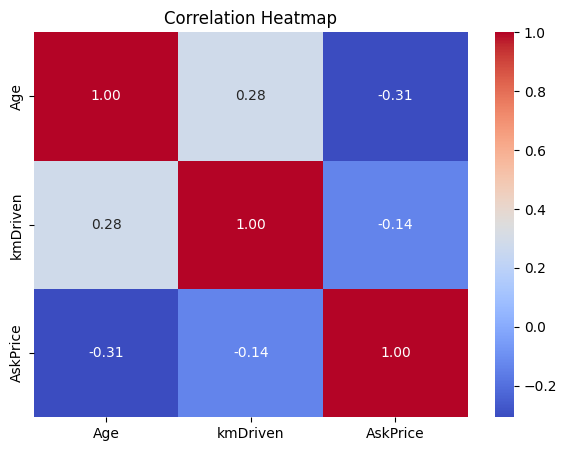

In [11]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    df[['Age', 'kmDriven', 'AskPrice']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap')
plt.show()

In [12]:
X = df[
    ['Age', 'kmDriven', 'Brand', 'model',
     'Transmission', 'Owner', 'FuelType']
]
y = df['AskPrice']
categorical_features = [
    'Brand',
    'model',
    'Transmission',
    'Owner',
    'FuelType'
]
preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ],
    remainder='passthrough'
)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 7049
Testing samples: 1763


In [13]:
model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ]
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MAE: 611878.76
MSE: 1669692744597.09
RMSE: 1292165.91
R2 Score: 0.3765


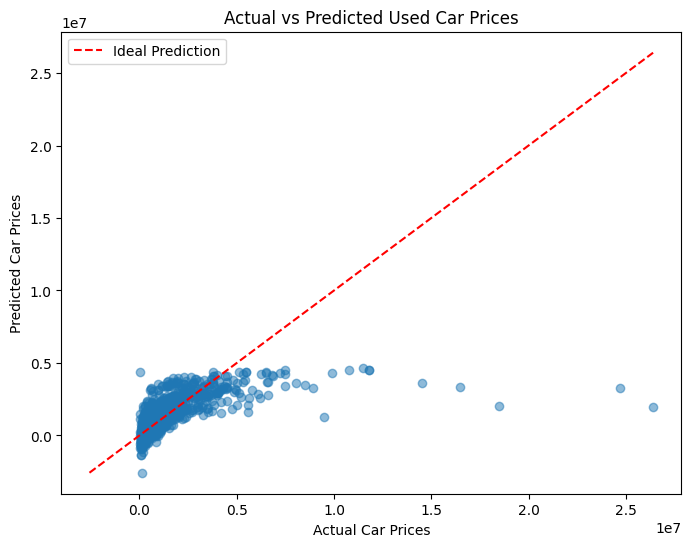

In [14]:
plt.figure(figsize=(8, 6))
plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())
plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    'r--',
    label='Ideal Prediction'
)
plt.xlabel('Actual Car Prices')
plt.ylabel('Predicted Car Prices')
plt.title('Actual vs Predicted Used Car Prices')
plt.legend()
plt.show()

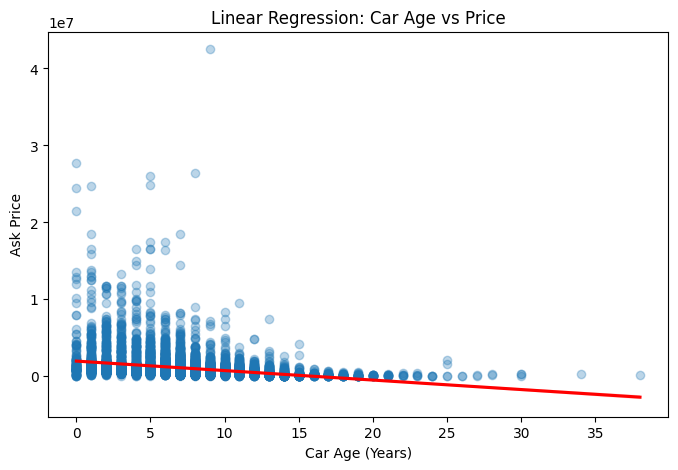

In [15]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x='Age',
    y='AskPrice',
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

plt.title('Linear Regression: Car Age vs Price')
plt.xlabel('Car Age (Years)')
plt.ylabel('Ask Price')
plt.show()

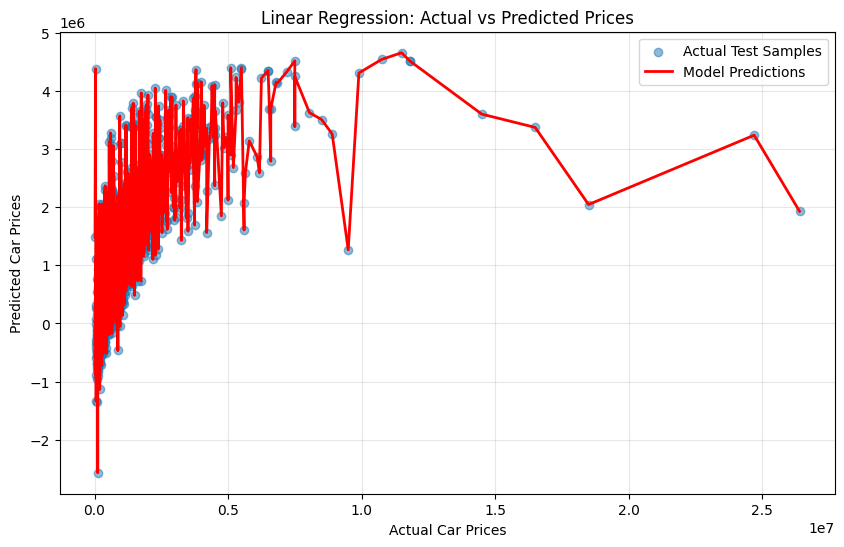

In [17]:
results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})
results = results.sort_values(by='Actual Price').reset_index(drop=True)
plt.figure(figsize=(10, 6))
plt.scatter(
    results['Actual Price'],
    results['Predicted Price'],
    alpha=0.5,
    label='Actual Test Samples'
)
plt.plot(
    results['Actual Price'],
    results['Predicted Price'],
    color='red',
    linewidth=2,
    label='Model Predictions'
)
plt.xlabel('Actual Car Prices')
plt.ylabel('Predicted Car Prices')
plt.title('Linear Regression: Actual vs Predicted Prices')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


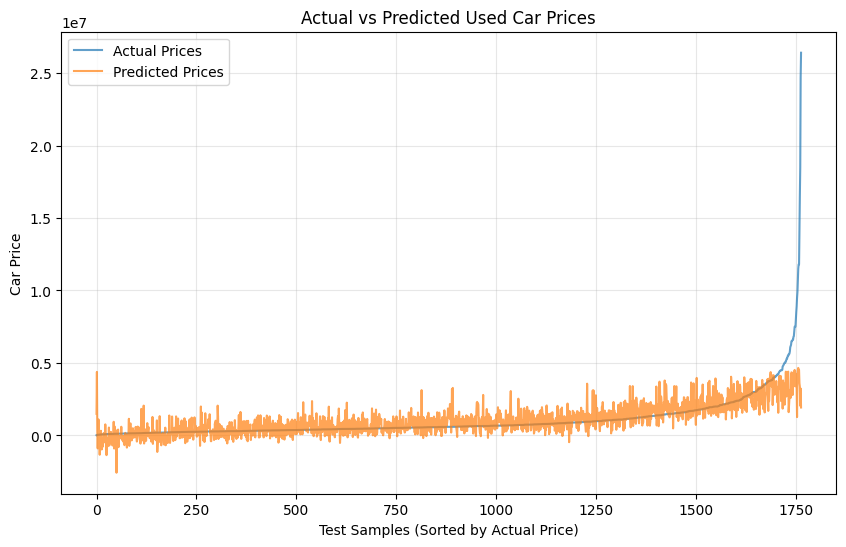

In [16]:

results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

results = results.sort_values(by='Actual Price')

plt.figure(figsize=(10, 6))

plt.plot(
    range(len(results)),
    results['Actual Price'].values,
    label='Actual Prices',
    alpha=0.7
)

plt.plot(
    range(len(results)),
    results['Predicted Price'].values,
    label='Predicted Prices',
    alpha=0.7
)

plt.xlabel('Test Samples (Sorted by Actual Price)')
plt.ylabel('Car Price')
plt.title('Actual vs Predicted Used Car Prices')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
